# GRU classifier — (b), (c)
Run All. Stop anytime and Run All again: finished runs are skipped, unfinished ones resume.
Full run ≈ 45 min on an M4 Pro CPU; with the pushed results it only re-plots (~1 min). `QUICK = True` = smoke test.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "common").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", 30)

In [2]:
from dataclasses import replace
from gru_classifier.train import Config, grid_search, summarize, predict_test, predict_texts
from gru_classifier.plots import plot_heatmap, plot_curves, plot_gap
from common.data import describe_split

QUICK = False
WORKERS = 4                      # parallel runs (2.4x faster on 8 P-cores)
SEEDS = [42, 7, 123]
BASE = Config()
if QUICK:
    BASE = Config(max_epochs=1)
describe_split()

,part,rows,negative,positive,positive %,texts also in train
0,train,5921,866,5055,85.4,0
1,val,1480,216,1264,85.4,0


## Model

In [3]:
import torch
from gru_classifier.model import GRUClassifier, count_parameters
from gru_classifier.text import Vocab
from common.data import get_split
train_df, val_df = get_split()
vocab = Vocab.build(train_df["reviews"], BASE.min_freq)
m = GRUClassifier(len(vocab), BASE.embed_dim, BASE.hidden_size, BASE.num_layers, BASE.bidirectional, BASE.dropout)
print(m)
ids, lengths = torch.randint(2, len(vocab), (4, 50)), torch.tensor([50, 30, 12, 7])
print("ids", tuple(ids.shape), "-> emb", tuple(m.embedding(ids).shape), "-> logits", tuple(m(ids, lengths).shape))
print(f"vocab {len(vocab):,} | params {count_parameters(m):,}")

GRUClassifier(
  (embedding): Embedding(7025, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)
ids (4, 50) -> emb (4, 50, 128) -> logits (4, 2)
vocab 7,025 | params 1,097,858


## Stage 1 — learning rate × hidden size

In [4]:
grid1 = {"lr": [1e-3, 3e-3, 1e-2], "hidden_size": [64, 128, 256]}
if QUICK: grid1 = {"lr": [1e-3], "hidden_size": [64]}
r1 = grid_search(grid1, base=BASE, workers=WORKERS)
s1 = summarize(r1, ["lr", "hidden_size"])
best1 = s1.iloc[0]
BASE = replace(BASE, lr=float(best1.lr), hidden_size=int(best1.hidden_size))
s1

,lr,hidden_size,val_f1,val_f1_std,train_f1,gap,val_acc,neg_recall,best_epoch,seconds,n_seeds
0,0.003,128,0.8307,NaN,0.9963,0.1656,0.9162,0.7037,7.0,178.6399,1
1,0.001,256,0.8298,NaN,0.9867,0.1569,0.9182,0.6759,9.0,339.8726,1
2,0.001,64,0.8223,NaN,0.9758,0.1535,0.9041,0.7731,13.0,140.8491,1
3,0.001,128,0.8214,NaN,0.9857,0.1643,0.9128,0.6759,10.0,210.1219,1
4,0.003,256,0.8156,NaN,0.9940,0.1784,0.9047,0.7176,7.0,290.0721,1
5,0.003,64,0.8153,NaN,0.9923,0.1770,0.9088,0.6759,8.0,102.0101,1
6,0.010,64,0.8152,NaN,0.9792,0.1640,0.9054,0.7083,6.0,87.8124,1
7,0.010,128,0.8054,NaN,0.9600,0.1546,0.9020,0.6759,5.0,142.3524,1
8,0.010,256,0.7720,NaN,0.8854,0.1134,0.8824,0.6389,2.0,137.3287,1


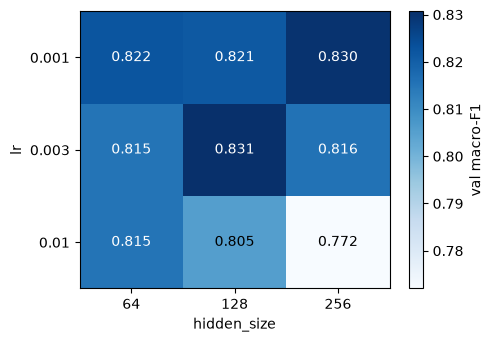

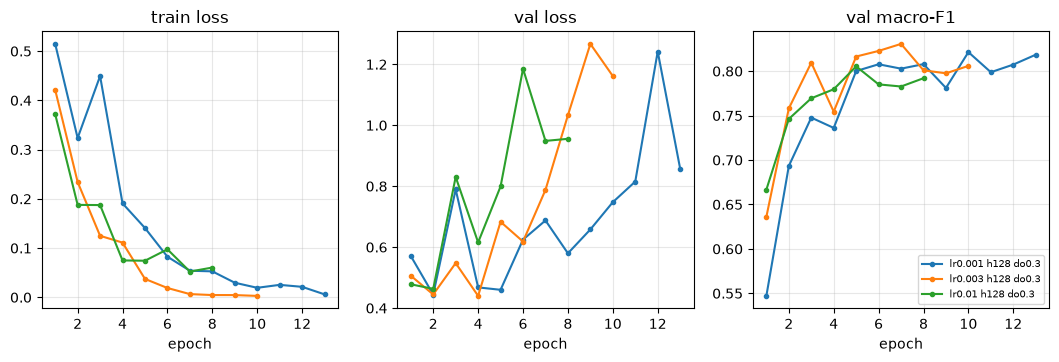

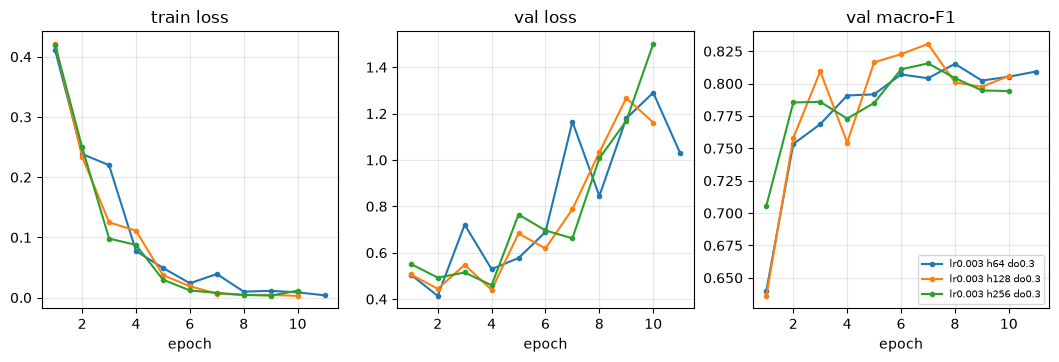

In [5]:
if len(s1) > 1:
    plot_heatmap(s1, "lr", "hidden_size", "stage1_lr_hidden")
    plot_curves(r1[r1.hidden_size == BASE.hidden_size].run_id, "stage1_lr_curves")
    plot_curves(r1[r1.lr == BASE.lr].run_id, "stage1_hidden_curves")

## Stage 2 — regularization: dropout × L2 weight decay

In [6]:
grid2 = {"dropout": [0.0, 0.3, 0.5], "weight_decay": [0.0, 1e-5, 1e-4]}
if QUICK: grid2 = {"dropout": [0.3], "weight_decay": [0.0]}
r2 = grid_search(grid2, base=BASE, workers=WORKERS)
s2 = summarize(r2, ["dropout", "weight_decay"])
best2 = s2.iloc[0]
BASE = replace(BASE, dropout=float(best2.dropout), weight_decay=float(best2.weight_decay))
s2

,dropout,weight_decay,val_f1,val_f1_std,train_f1,gap,val_acc,neg_recall,best_epoch,seconds,n_seeds
0,0.5,0.00010,0.8536,NaN,0.9940,0.1403,0.9270,0.7500,15.0,216.4458,1
1,0.3,0.00010,0.8466,NaN,0.9990,0.1524,0.9236,0.7361,14.0,241.2339,1
2,0.5,0.00000,0.8457,NaN,0.9943,0.1486,0.9250,0.7130,15.0,239.5591,1
3,0.5,0.00001,0.8415,NaN,0.9900,0.1485,0.9196,0.7454,12.0,233.3843,1
4,0.3,0.00000,0.8307,NaN,0.9963,0.1656,0.9162,0.7037,7.0,178.6399,1
5,0.0,0.00001,0.8245,NaN,1.0000,0.1755,0.9162,0.6620,9.0,184.3330,1
6,0.3,0.00001,0.8192,NaN,0.9783,0.1592,0.9068,0.7222,6.0,139.1186,1
7,0.0,0.00010,0.8189,NaN,0.9950,0.1761,0.9061,0.7269,13.0,230.7775,1
8,0.0,0.00000,0.7995,NaN,1.0000,0.2005,0.9061,0.6065,8.0,167.2539,1


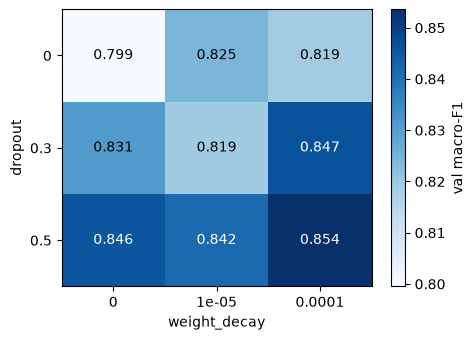

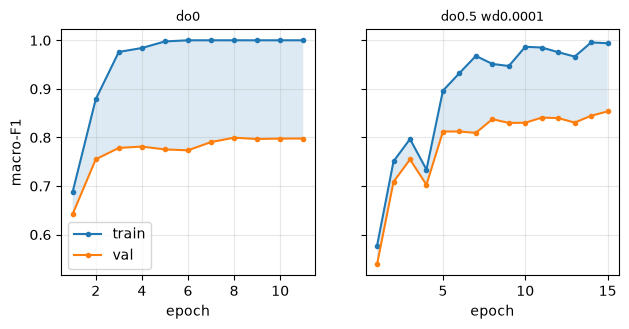

In [7]:
if len(s2) > 1:
    plot_heatmap(s2, "dropout", "weight_decay", "stage2_dropout_l2")
    none = r2[(r2.dropout == 0) & (r2.weight_decay == 0)].run_id.iloc[0]
    best = r2[(r2.dropout == BASE.dropout) & (r2.weight_decay == BASE.weight_decay)].run_id.iloc[0]
    plot_gap([none, best], "stage2_gap_no_reg_vs_best")

## Stage 3 — word dropout (augmentation)

In [8]:
grid3 = {"word_dropout": [0.0, 0.1, 0.2]}
if QUICK: grid3 = {"word_dropout": [0.1]}
r3 = grid_search(grid3, base=BASE, workers=WORKERS)
s3 = summarize(r3, ["word_dropout"])
BASE = replace(BASE, word_dropout=float(s3.iloc[0].word_dropout))
s3

,word_dropout,val_f1,val_f1_std,train_f1,gap,val_acc,neg_recall,best_epoch,seconds,n_seeds
0,0.0,0.8536,NaN,0.9940,0.1403,0.9270,0.7500,15.0,216.4458,1
1,0.2,0.8529,NaN,0.9686,0.1157,0.9284,0.7269,10.0,140.5573,1
2,0.1,0.8363,NaN,0.9442,0.1079,0.9142,0.7685,7.0,110.2994,1


## Stage 4 — final config over 3 seeds

In [9]:
r4 = grid_search({"lr": [BASE.lr]}, seeds=SEEDS if not QUICK else [42], base=BASE, workers=WORKERS)
print(BASE)
r4[["seed", "val_macro_f1", "val_accuracy", "val_neg_recall", "train_macro_f1", "best_epoch"]].describe().loc[["mean", "std"]].round(4)

Config(lr=0.003, hidden_size=128, embed_dim=128, num_layers=1, bidirectional=True, dropout=0.5, max_len=200, min_freq=2, batch_size=64, max_epochs=15, patience=3, weight_decay=0.0001, word_dropout=0.0, pooling='last', train_frac=1.0, class_weighted=True, grad_clip=1.0, seed=42)


,seed,val_macro_f1,val_accuracy,val_neg_recall,train_macro_f1,best_epoch
mean,57.3333,0.8580,0.9286,0.7670,0.9901,13.0
std,59.5007,0.0136,0.0059,0.0377,0.0037,2.0


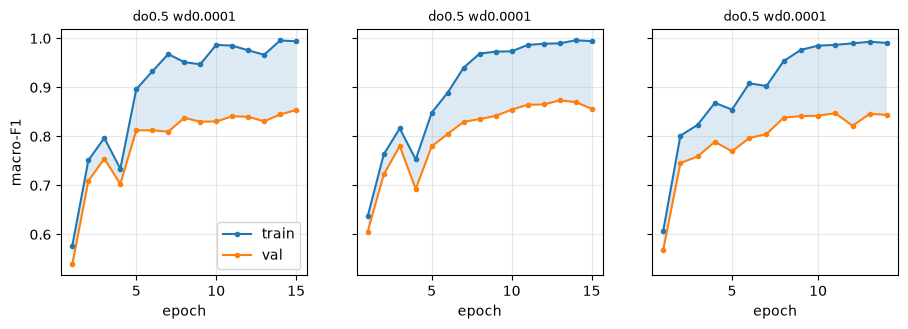

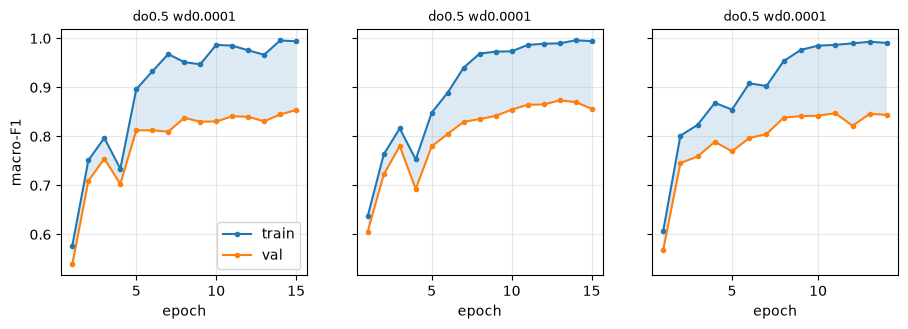

In [10]:
plot_gap(r4.run_id, "stage4_final_seeds")

## Stage 5 — pooling: last hidden state vs mean+max over all steps

In [11]:
from gru_classifier.experiments import seed_runs, complexity_sweep, data_size_curve
r5 = seed_runs(replace(BASE, pooling="meanmax"), SEEDS if not QUICK else [42], workers=WORKERS)
pool = pd.DataFrame({"last": r4.val_macro_f1.describe()[["mean", "std"]], "meanmax": r5.val_macro_f1.describe()[["mean", "std"]]}).round(4)
if r5.val_macro_f1.mean() > r4.val_macro_f1.mean():
    BASE, r4 = replace(BASE, pooling="meanmax"), r5
pool

,last,meanmax
mean,0.8580,0.8530
std,0.0136,0.0054


## Ensemble 3 seeds + decision threshold (tuned on val)

,model,macro_f1@0.5,acc@0.5,neg_recall@0.5,best_threshold,macro_f1@best,acc@best,neg_recall@best
0,seed 42,0.8536,0.9270,0.7500,0.42,0.8558,0.9291,0.7407
1,seed 7,0.8733,0.9351,0.8102,0.21,0.8754,0.9405,0.7454
2,seed 123,0.8472,0.9236,0.7407,0.21,0.8507,0.9311,0.6759
3,ensemble,0.8661,0.9331,0.7731,0.42,0.8743,0.9399,0.7454


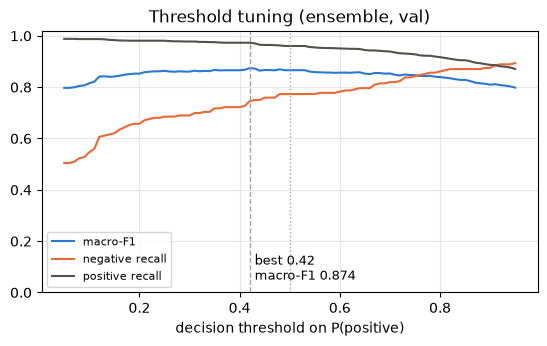

In [12]:
from gru_classifier.optimize import compare
from gru_classifier.plots import plot_threshold
table, curve = compare(list(r4.run_id))
THRESHOLD = float(table.loc[table.model == "ensemble", "best_threshold"].iloc[0])
plot_threshold(curve)
table

## Underfitting vs overfitting

,weight_decay,train_macro_f1,val_macro_f1,best_epoch
0,0.0000,0.9943,0.8457,15
1,0.0000,0.9900,0.8415,12
2,0.0001,0.9940,0.8536,15
3,0.0010,0.8772,0.8185,7
4,0.0030,0.7377,0.7303,3
5,0.0100,0.7783,0.7335,10
6,0.1000,0.5614,0.5476,3


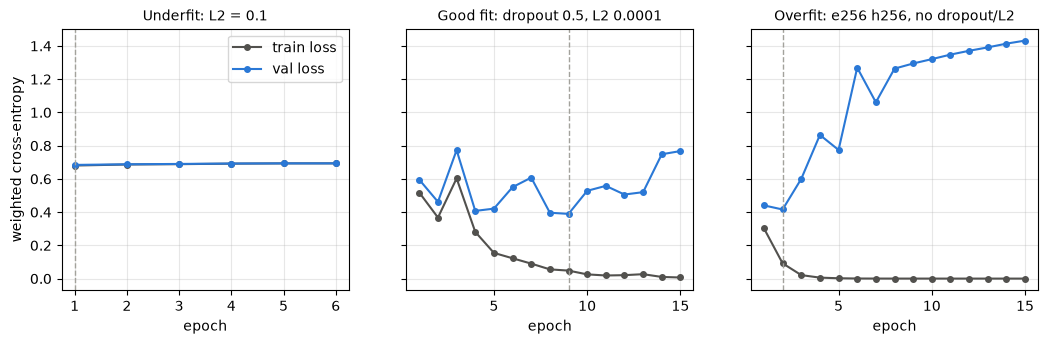

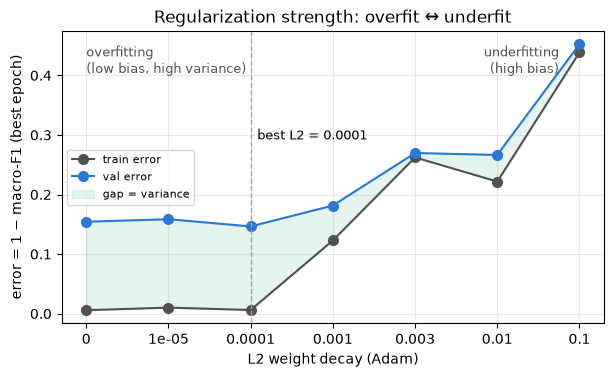

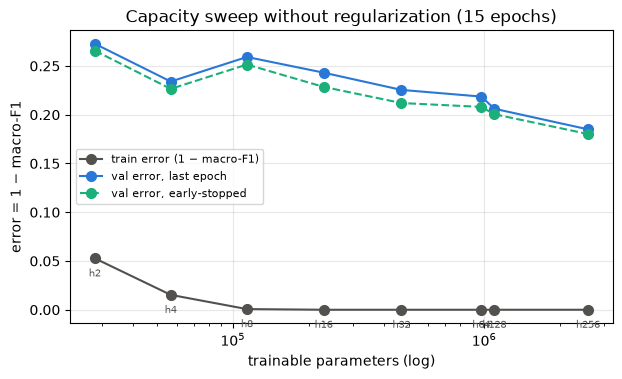

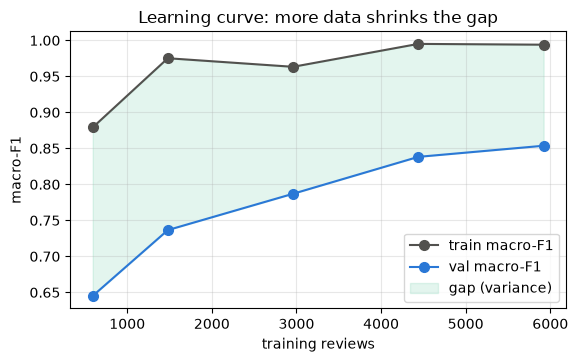

In [13]:
from gru_classifier.experiments import reg_sweep
from gru_classifier.plots import plot_fit_regimes, plot_complexity, plot_learning_curve, plot_reg_curve
rs = reg_sweep(BASE, workers=WORKERS) if not QUICK else reg_sweep(BASE, wds=(0.0, 1e-1))
cs = complexity_sweep(BASE, workers=WORKERS) if not QUICK else complexity_sweep(BASE, sizes=[(4, 2), (32, 16)])
ds = data_size_curve(BASE, workers=WORKERS) if not QUICK else data_size_curve(BASE, fracs=(0.25, 1.0))
under = rs.sort_values("weight_decay").iloc[-1]
big = cs.sort_values("params").iloc[-1]
good = r4[r4.seed == 42].iloc[0]
plot_fit_regimes({
    f"Underfit: L2 = {under.weight_decay:g}": under.run_id,
    f"Good fit: dropout {BASE.dropout:g}, L2 {BASE.weight_decay:g}": good.run_id,
    f"Overfit: e{big.embed_dim} h{big.hidden_size}, no dropout/L2": big.run_id})
plot_reg_curve(rs)
plot_complexity(cs)
plot_learning_curve(ds)
rs[["weight_decay", "train_macro_f1", "val_macro_f1", "best_epoch"]].round(4)

## Test predictions → results/gru_classifier/test_predictions.csv

In [14]:
pred = predict_test(list(r4.run_id), threshold=THRESHOLD)
print(BASE, "| threshold", THRESHOLD)
pred.predictions.value_counts()

Config(lr=0.003, hidden_size=128, embed_dim=128, num_layers=1, bidirectional=True, dropout=0.5, max_len=200, min_freq=2, batch_size=64, max_epochs=15, patience=3, weight_decay=0.0001, word_dropout=0.0, pooling='last', train_frac=1.0, class_weighted=True, grad_clip=1.0, seed=42) | threshold 0.42


predictions
1    1622
0     229
Name: count, dtype: int64

In [15]:
examples = ["Love these shoes, very comfortable!", "Not comfortable at all, returned them.",
            "Not bad for the price.", "Looks great but it ripped after one wash."]
pd.DataFrame({"review": examples, "prob_positive": predict_texts(r4.run_id.iloc[0], examples).round(3)})

,review,prob_positive
0,"Love these shoes, very comfortable!",1.000
1,"Not comfortable at all, returned them.",0.000
2,Not bad for the price.,0.006
3,Looks great but it ripped after one wash.,0.097
